Accepted: 997,574 / 500,000
Final number of samples: 500,000


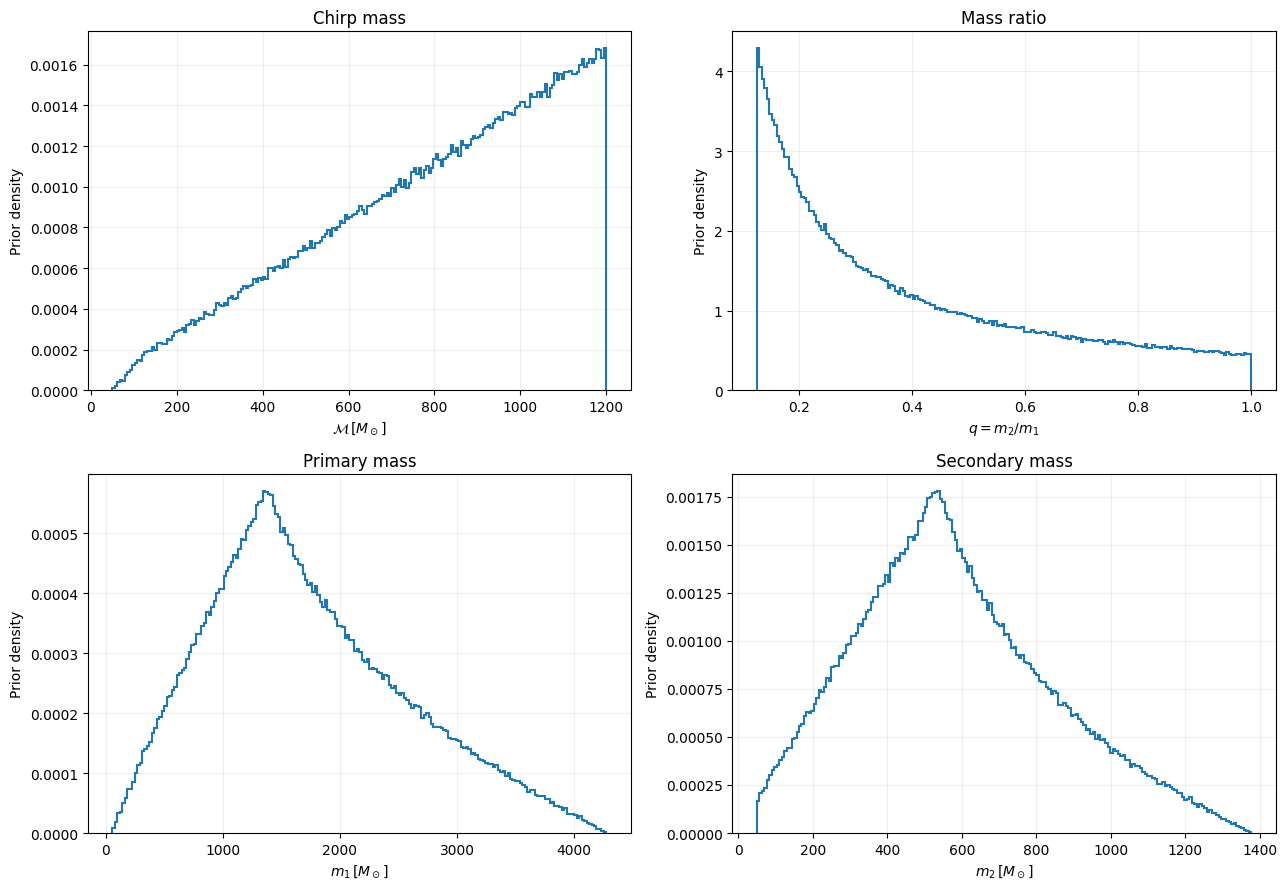

In [7]:
import bilby
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# Priors from Dingo
# =========================================================

chirp_prior = bilby.gw.prior.UniformInComponentsChirpMass(
    minimum=50.0,
    maximum=1200.0,
)

q_prior = bilby.gw.prior.UniformInComponentsMassRatio(
    minimum=0.125,
    maximum=1.0,
)

# Component-mass constraints
m1_min, m1_max = 50.0, 4500.0
#m2_min, m2_max = 20.0, 1500.0

m2_min, m2_max = 50.0, 4500.0


# =========================================================
# Draw samples
# =========================================================

N = 500_000

mc_list = []
q_list = []
m1_list = []
m2_list = []

n_accepted = 0

while n_accepted < N:

    # Draw a batch
    n_draw = 500_000

    mc = chirp_prior.sample(n_draw)
    q = q_prior.sample(n_draw)

    # -----------------------------------------------------
    # Convert chirp mass + mass ratio -> component masses
    # -----------------------------------------------------

    m1 = mc * (1 + q)**(1/5) / q**(3/5)
    m2 = q * m1

    # -----------------------------------------------------
    # Apply Dingo's component-mass constraints
    # -----------------------------------------------------

    mask = (
        (m1 >= m1_min) &
        (m1 <= m1_max) &
        (m2 >= m2_min) &
        (m2 <= m2_max)
    )

    mc_list.append(mc[mask])
    q_list.append(q[mask])
    m1_list.append(m1[mask])
    m2_list.append(m2[mask])

    n_accepted += np.sum(mask)

    print(f"Accepted: {n_accepted:,} / {N:,}", end="\r")


# Concatenate and truncate to exactly N samples
chirp_mass = np.concatenate(mc_list)[:N]
mass_ratio = np.concatenate(q_list)[:N]
mass_1 = np.concatenate(m1_list)[:N]
mass_2 = np.concatenate(m2_list)[:N]

print(f"\nFinal number of samples: {len(chirp_mass):,}")


# =========================================================
# Plot distributions
# =========================================================

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Chirp mass
axes[0, 0].hist(
    chirp_mass,
    bins=200,
    density=True,
    histtype="step",
    linewidth=1.5,
)

axes[0, 0].set_xlabel(r"$\mathcal{M}\,[M_\odot]$")
axes[0, 0].set_ylabel("Prior density")
axes[0, 0].set_title("Chirp mass")


# Mass ratio
axes[0, 1].hist(
    mass_ratio,
    bins=200,
    density=True,
    histtype="step",
    linewidth=1.5,
)

axes[0, 1].set_xlabel(r"$q=m_2/m_1$")
axes[0, 1].set_ylabel("Prior density")
axes[0, 1].set_title("Mass ratio")


# Primary mass
axes[1, 0].hist(
    mass_1,
    bins=200,
    density=True,
    histtype="step",
    linewidth=1.5,
)

axes[1, 0].set_xlabel(r"$m_1\,[M_\odot]$")
axes[1, 0].set_ylabel("Prior density")
axes[1, 0].set_title("Primary mass")


# Secondary mass
axes[1, 1].hist(
    mass_2,
    bins=200,
    density=True,
    histtype="step",
    linewidth=1.5,
)

axes[1, 1].set_xlabel(r"$m_2\,[M_\odot]$")
axes[1, 1].set_ylabel("Prior density")
axes[1, 1].set_title("Secondary mass")


for ax in axes.flat:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

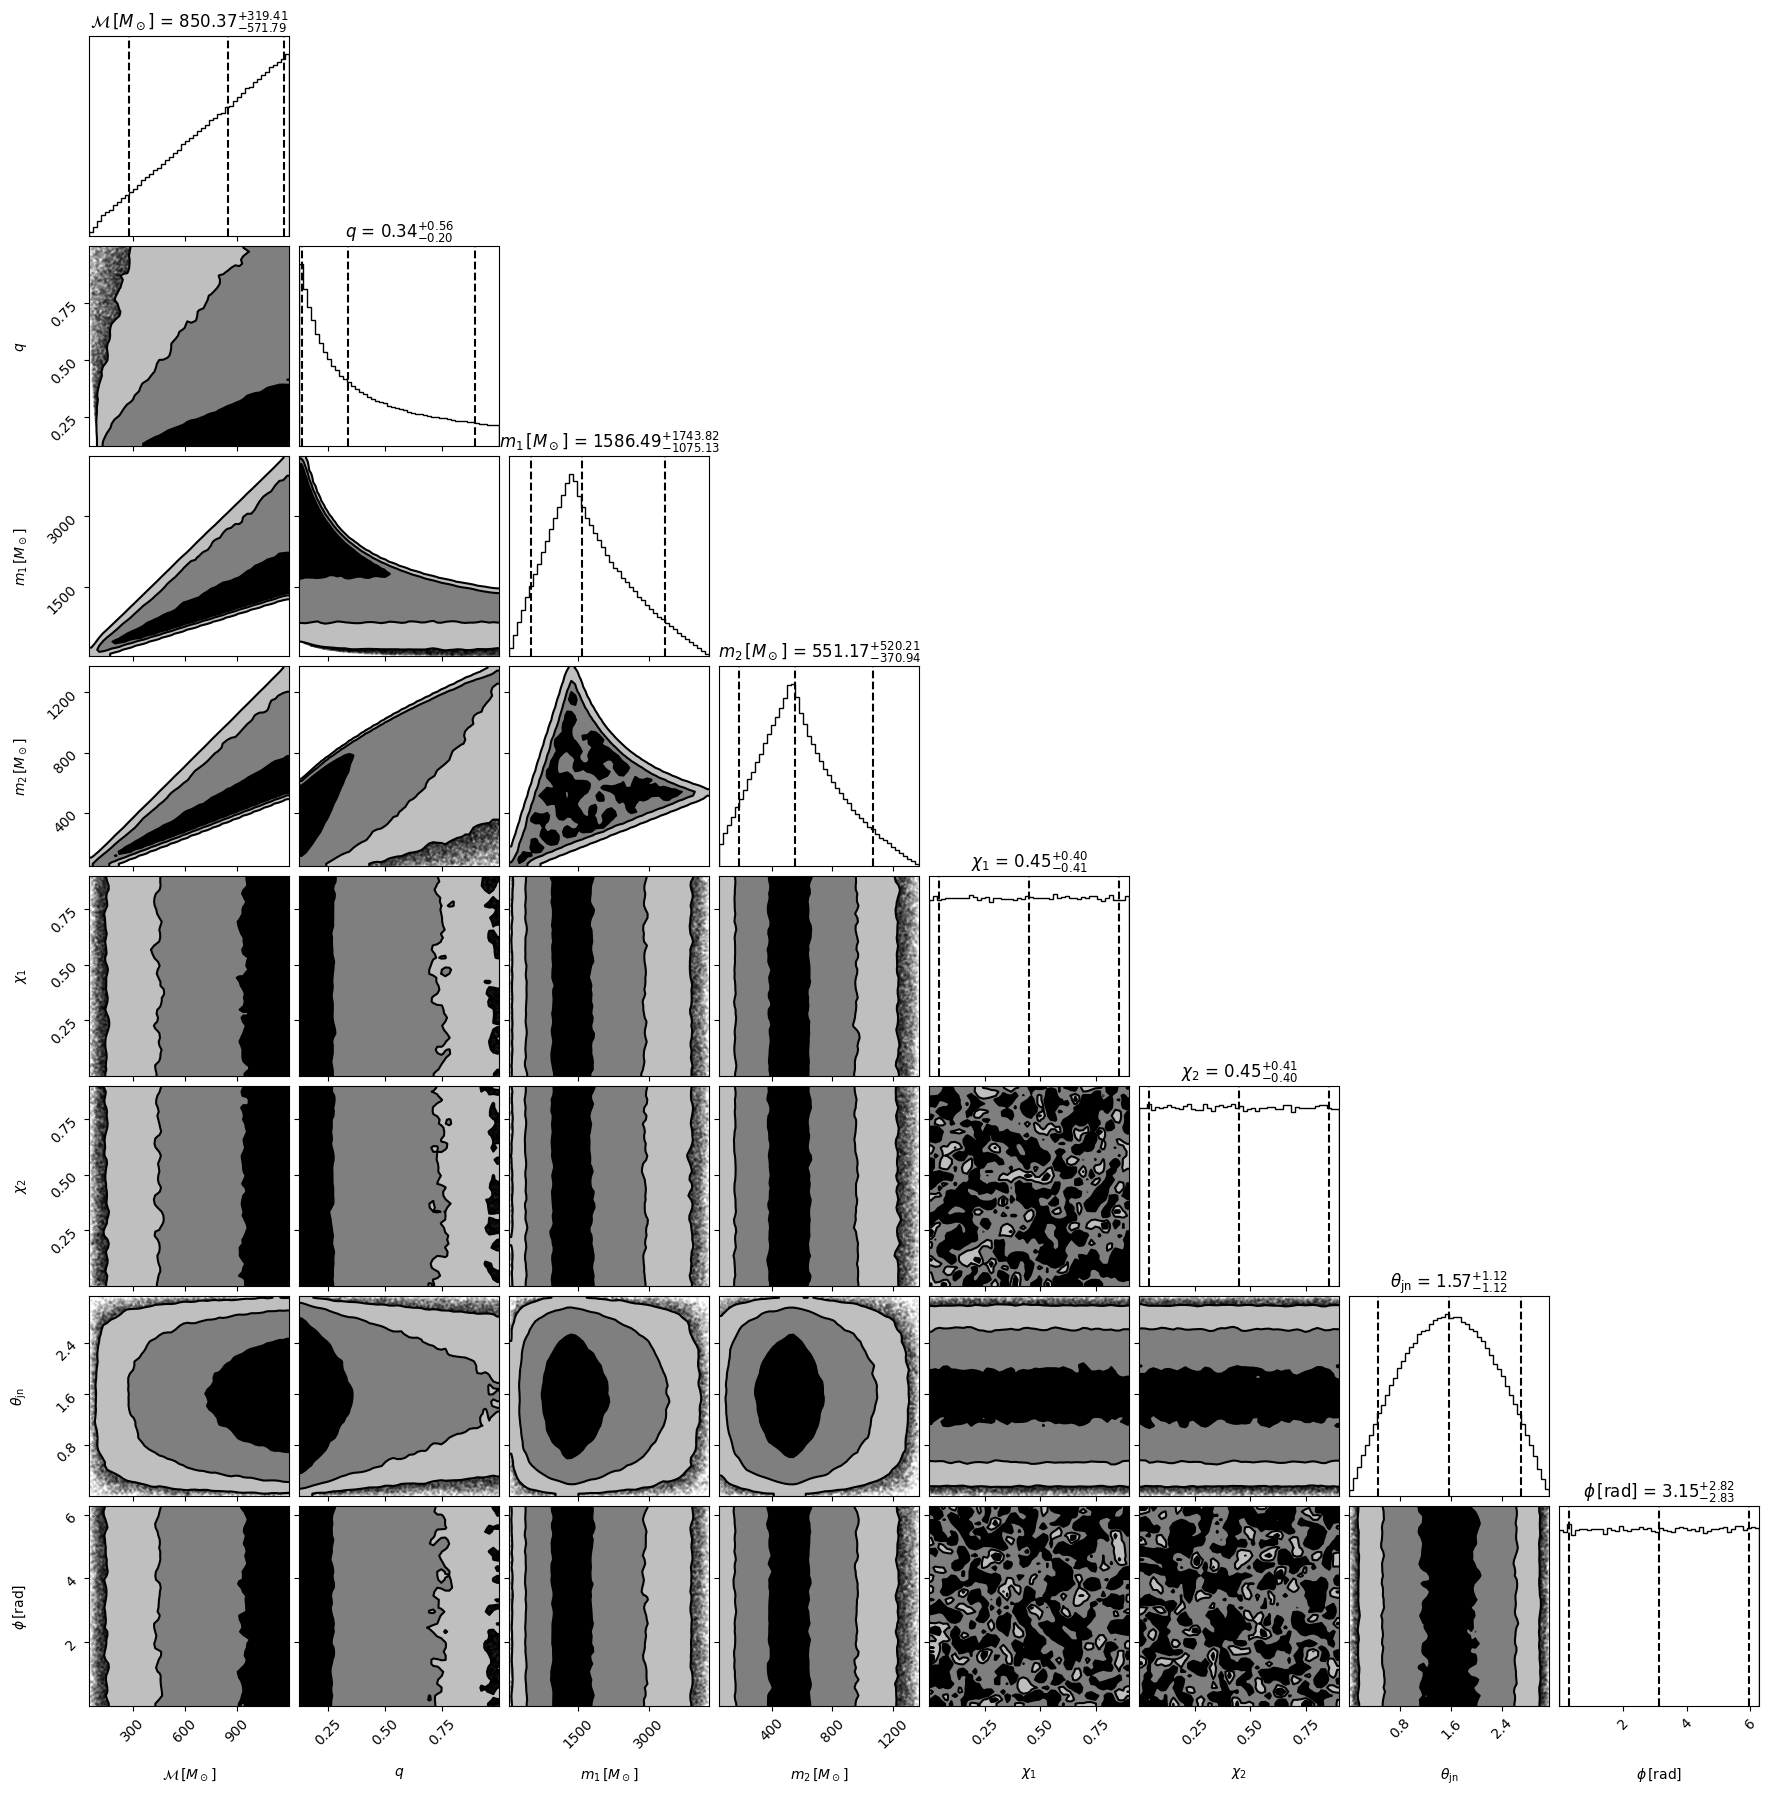

In [8]:
import corner

# =========================================================
# Sample the remaining parameters
# =========================================================

N = len(chirp_mass)

# Phase: uniform [0, 2pi)
phase = np.random.uniform(0, 2 * np.pi, N)

# Aligned spins:
# chi_1 and chi_2 are uniform in [0, 0.9]
chi_1 = np.random.uniform(0, 0.9, N)
chi_2 = np.random.uniform(0, 0.9, N)

# theta_jn: Sine prior
# p(theta) ∝ sin(theta), theta in [0, pi]
theta_jn = np.arccos(
    np.random.uniform(-1, 1, N)
)


# =========================================================
# Construct array for corner plot
# =========================================================

corner_samples = np.column_stack([
    chirp_mass,
    mass_ratio,
    mass_1,
    mass_2,
    chi_1,
    chi_2,
    theta_jn,
    phase,
])

labels = [
    r"$\mathcal{M}\,[M_\odot]$",
    r"$q$",
    r"$m_1\,[M_\odot]$",
    r"$m_2\,[M_\odot]$",
    r"$\chi_1$",
    r"$\chi_2$",
    r"$\theta_{\rm jn}$",
    r"$\phi\,[\mathrm{rad}]$",
]


# =========================================================
# Corner plot
# =========================================================

fig = corner.corner(
    corner_samples,
    labels=labels,
    bins=50,
    smooth=0.8,
    show_titles=True,
    title_fmt=".2f",
    quantiles=[0.05, 0.5, 0.95],
    levels=(0.393, 0.865, 0.989),
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    max_n_ticks=4,
)

plt.show()

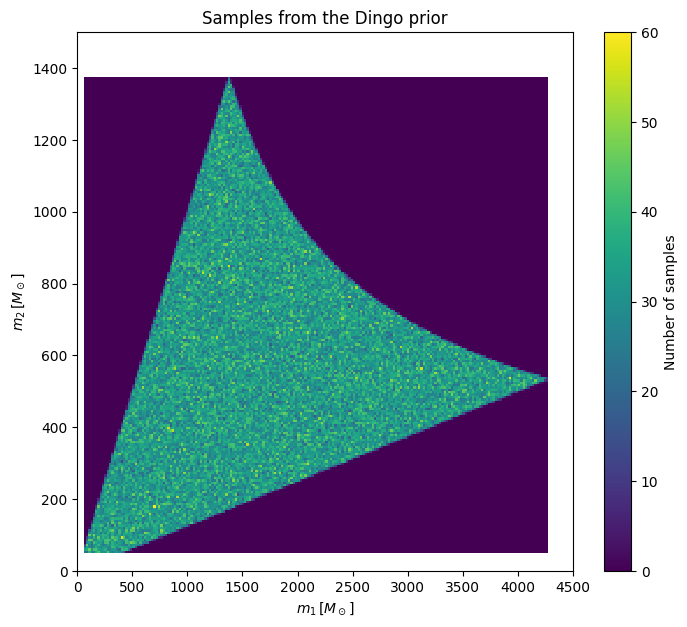

In [9]:
plt.figure(figsize=(8, 7))

plt.hist2d(
    mass_1,
    mass_2,
    bins=200,
)

plt.xlabel(r"$m_1\,[M_\odot]$")
plt.ylabel(r"$m_2\,[M_\odot]$")
plt.title("Samples from the Dingo prior")

plt.xlim(0, 4500)
plt.ylim(0, 1500)

plt.colorbar(label="Number of samples")
plt.show()